# Random Forest (owner: Sriniket Deeduvanu)

In [1]:
import os, sys
from pathlib import Path

# --- Colab only: clone the repo and move into it ---
REPO = "ML-Project-Earthquake-Damage"
GITHUB_URL = "https://github.com/ayaanGH06/ML-Project-Earthquake-Damage.git"  # private repo: use a token URL in Colab, never commit it

if "google.colab" in sys.modules and not os.path.exists("src"):
    if not os.path.exists(REPO):
        !git clone {GITHUB_URL}
    %cd {REPO}
    !pip install -q -r requirements.txt

# --- Local Jupyter: notebooks run from notebooks/, so go up to the repo root ---
if Path.cwd().name == "notebooks":
    os.chdir("..")

# --- Data: the 3 CSVs must be in data/raw/ (see README for the download link) ---
DATA_DIR = Path("data/raw")
needed = ["train_values.csv", "train_labels.csv", "test_values.csv"]
missing = [f for f in needed if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(
        f"Missing {missing} in {DATA_DIR.resolve()}. "
        "Download them from the Google Drive link in the README and place them in data/raw/."
    )

from src.data import load_raw, train_val_split, build_scaled_preprocessor, build_tree_preprocessor
from src.evaluate import evaluate_model, micro_f1

X, y, X_test = load_raw(DATA_DIR)
X_train, X_val, y_train, y_val = train_val_split(X, y)
print(X_train.shape, X_val.shape)

(208480, 38) (52121, 38)


random_forest: micro-F1 = 0.6629
              precision    recall  f1-score   support

           1       0.45      0.78      0.57      5025
           2       0.78      0.60      0.68     29652
           3       0.63      0.73      0.68     17444

    accuracy                           0.66     52121
   macro avg       0.62      0.71      0.64     52121
weighted avg       0.70      0.66      0.67     52121



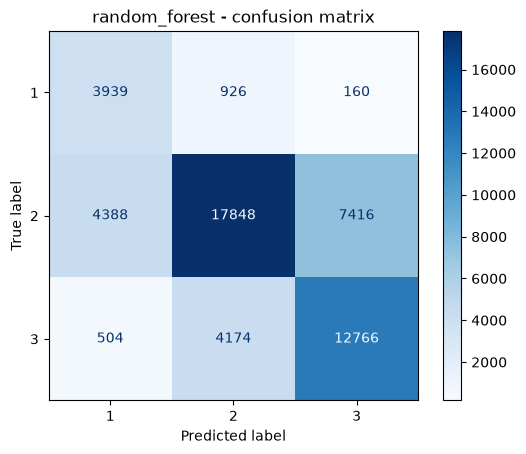

Validation accuracy: 0.6629
Training score: 0.7061
Validation score: 0.6629


In [2]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

# Build a pipeline so preprocessing is fitted only on training data
rf_model = Pipeline([
    ("preprocessor", build_tree_preprocessor(X_train)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=10,
        min_samples_leaf=4,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

# Evaluate on unseen validation data
y_val_pred_rf = rf_model.predict(X_val)

rf_f1 = evaluate_model(
    "random_forest",
    y_val,
    y_val_pred_rf
)

print(f"Validation accuracy: {accuracy_score(y_val, y_val_pred_rf):.4f}")
print(f"Training score: {rf_model.score(X_train, y_train):.4f}")
print(f"Validation score: {rf_model.score(X_val, y_val):.4f}")